# Figures 2 and 3: scaling collapse and compute-optimal frontier

Final camera-ready version. Both figures are drawn from the archived sweep in `results.zip`: 238 "slow" rounds (fewer trials, used where $C = ND\min(N,D) \ge 10^6$) and 3,335 "fast" rounds (many trials, used below that), on a grid of 21 values of $N$ (10 to 1000) by 31 values of $D$ (10 to 10,000), at $(\alpha_1, \alpha_2) = (1.0, 0.3)$. Nothing is recomputed here.

Printed font sizes (both figures are placed at `0.5\textwidth` = 2.75 in): tick labels 7 pt, axis labels 8 pt; legend 7 pt in Figure 2 and 4.5 pt in Figure 3. Figure 2 is drawn at its printed size. Figure 3 keeps its original 8 x 6 in canvas and settings, with only the font sizes changed; LaTeX scales it by about 0.349, and the source font sizes are chosen so they print at the sizes above.

In [ ]:
# Load the archived results (no download, no fallback: a missing file is an error)

import io, re, zipfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.ticker as ticker
from scipy.special import gamma

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt); each figure is drawn at its size on the page
FIG_W, FIG_H = 2.75, 2.3          # inches; 0.5\textwidth in the NeurIPS template
FS_TICK, FS_LABEL, FS_LEGEND = 7, 8, 7

# EXPERIMENT PARAMETERS (must match the sweep that produced the archive)
ALPHA1 = 1.0
ALPHA2 = 0.3
NUM_NS = 21
NUM_TS = 31
NS = np.logspace(1, 3, NUM_NS)  # N from 10 to 1000
TS = np.logspace(1, 4, NUM_TS)  # D from 10 to 10000

RESULTS_ZIP = "results.zip"


def compute_cost(N, T):
    """Compute cost metric: N * T * min(N, T)"""
    return N * T * np.minimum(N, T)


def load_results(path=RESULTS_ZIP):
    """Average all rounds. 'Slow' rounds (fewer trials, used where compute >= 1e6)
    and 'fast' rounds (many trials, used below that) are combined cell by cell."""
    with zipfile.ZipFile(path) as z:
        names = z.namelist()
        slow = sorted(n for n in names if re.fullmatch(r"results/resultsSparseRound\d+\.npy", n))
        fast = sorted(n for n in names if re.fullmatch(r"results/fastOnly/resultsSparseRound\d+\.npy", n))
        if not slow or not fast:
            raise FileNotFoundError(f"no result rounds found in {path}")
        results_slow = sum(np.load(io.BytesIO(z.read(n))) for n in slow) / len(slow)
        results_fast = sum(np.load(io.BytesIO(z.read(n))) for n in fast) / len(fast)
    use_slow = np.array([[compute_cost(int(N), int(T)) >= 10**6 for T in TS] for N in NS])
    print(f"Loaded {len(slow)} slow and {len(fast)} fast rounds")
    return np.where(use_slow, results_slow, results_fast)


results = load_results()
assert results.shape == (NUM_NS, NUM_TS) and np.all(results > 0)


Loaded 238 slow and 3335 fast rounds


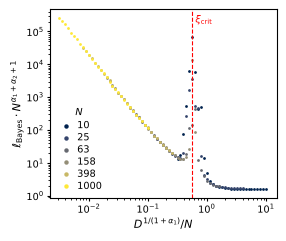

In [ ]:
# FIGURE 2: scaling collapse

def make_scaling_collapse_figure(results, step=4):
    """x = D^(1/(1+alpha1)) / N,  y = loss * N^(alpha1 + alpha2 + 1).
    Curves for different N collapse; the dashed line marks xi_crit = 1/Gamma(alpha1/(1+alpha1))."""
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), layout="constrained")

    indices = list(range(0, NUM_NS, step))
    colors = cm.cividis(np.linspace(0.0, 1.0, len(indices)))
    for idx, i in enumerate(indices):
        N = NS[i]
        xs = np.power(TS, 1 / (1 + ALPHA1)) / N
        ys = results[i, :] * N ** (ALPHA1 + ALPHA2 + 1)
        ax.scatter(xs, ys, c=[colors[idx]], s=4, linewidths=0, label=f'{int(N)}')

    x_crit = 1 / gamma(1 - 1 / (ALPHA1 + 1))
    ax.axvline(x_crit, color='red', linestyle='--', linewidth=0.8)
    ax.text(x_crit * 1.12, 0.97, r'$\xi_{\mathrm{crit}}$', color='red', fontsize=FS_LEGEND,
            transform=ax.get_xaxis_transform(), ha='left', va='top')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(2.2e-3, 15)
    ax.set_xlabel(r'$D^{1/(1+\alpha_1)}/N$', fontsize=FS_LABEL, labelpad=1)
    ax.set_ylabel(r'$\ell_{\mathrm{Bayes}}\cdot N^{\alpha_1+\alpha_2+1}$', fontsize=FS_LABEL, labelpad=1)
    ax.tick_params(which='both', labelsize=FS_TICK, pad=1.5)
    ax.tick_params(which='major', length=2.5)
    ax.tick_params(which='minor', length=1.5)
    ax.legend(title='$N$', loc='lower left', fontsize=FS_LEGEND, title_fontsize=FS_LEGEND,
              frameon=False, handletextpad=0.1, borderaxespad=0.3, labelspacing=0.25,
              markerscale=1.6)
    return fig


fig2 = make_scaling_collapse_figure(results, step=4)
fig2.savefig("../figures/Figure2.pdf")
fig2.savefig("../figures/Figure2.png", dpi=300)
plt.show()


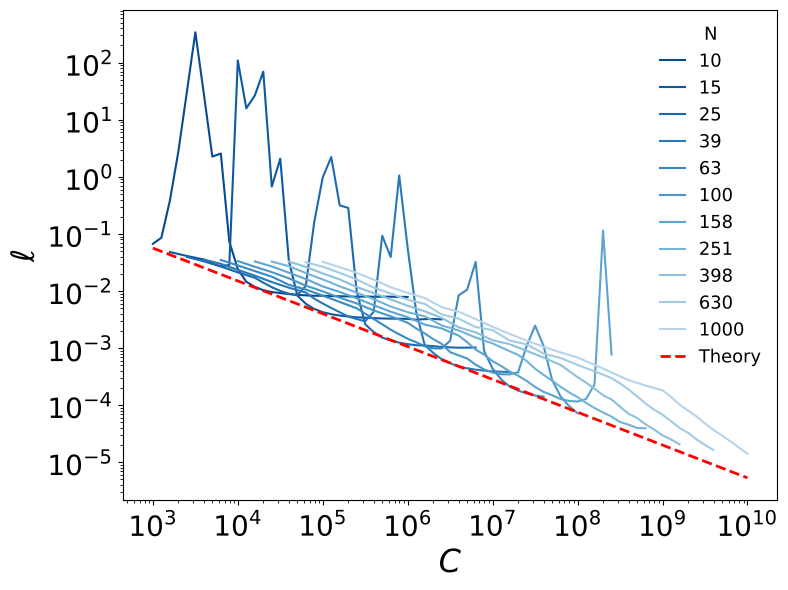

In [ ]:
# FIGURE 3: loss versus compute, with the compute-optimal frontier
#
# Drawn with the original settings (8 x 6 in canvas, original line widths and
# legend layout); only font sizes differ. LaTeX scales the PDF to 0.5\textwidth,
# a factor of about 0.349, so the source sizes below print as
# tick labels 7 pt, axis labels 8 pt, legend 4.5 pt.

PRINT_SCALE = 0.3487                                   # 2.75 in / PDF width (7.89 in)
F3_TICK, F3_LABEL, F3_LEGEND = 7 / PRINT_SCALE, 8 / PRINT_SCALE, 4.5 / PRINT_SCALE


def make_compute_scaling_figure(results, step=2):
    """Each curve is a fixed N with D swept; the dashed line is the predicted
    frontier  loss ~ C^(-(alpha1 + alpha2 + 1)/(3 + alpha1))."""
    fig, ax = plt.subplots(figsize=(8, 6))

    indices = list(range(0, NUM_NS, step))
    colors = cm.Blues(np.linspace(0.3, 0.9, len(indices)))[::-1]
    for idx, i in enumerate(indices):
        N = NS[i]
        computes = compute_cost(N, TS)
        losses = results[i, :]
        ax.plot(computes, losses, c=colors[idx], linewidth=1.5, label=f'{int(N)}')

    cs = np.logspace(3, 10, 70)
    exponent = -(ALPHA1 + ALPHA2 + 1) / (3 + ALPHA1)
    ax.plot(cs, 3 * cs ** exponent, color='red', linestyle='--',
            linewidth=2, label='Theory')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$C$', fontsize=F3_LABEL)
    ax.set_ylabel(r'$ℓ$', fontsize=F3_LABEL)
    # one labelled tick per decade, minor ticks in between
    ax.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=30))
    ax.xaxis.set_minor_locator(ticker.LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=300))
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    ax.tick_params(labelsize=F3_TICK)
    ax.legend(title='N', loc='upper right', fontsize=F3_LEGEND, title_fontsize=F3_LEGEND,
              handlelength=1.34, frameon=False)

    plt.tight_layout()
    return fig


fig3 = make_compute_scaling_figure(results, step=2)
fig3.savefig("../figures/Figure3.pdf", bbox_inches='tight')
fig3.savefig("../figures/Figure3.png", dpi=300, bbox_inches='tight')
plt.show()


## Data generation (original sweep code, for reference; not re-run here)

The cell below is the sweep code as found in the original working notebook. As found, it is set to $\alpha_1 = 0.3$; Figures 2 and 3 use the archived sweep at $(\alpha_1, \alpha_2) = (1.0, 0.3)$. It takes many hours on CPU and is not needed to reproduce the figures.

In [ ]:
import numpy as np
import time

print("Start \n")

M=20000
N=10000
D=10000
numTrials=10
alpha1=0.3
alpha2=0.3

import numpy as np

def generate_matrix(M, D, p, mags):
    '''Generate an MxD matrix where for each row i:
    - Elements are 0 with probability 1-p[i],
    - +mags[i] with probability p[i]/2,
    - -mags[i] with probability p[i]/2.

    Parameters:
    M (int): Number of rows.
    D (int): Number of columns.
    p (list or np.ndarray): List of probabilities for each row.
    mags (list or np.ndarray): List of magnitudes for each row.

    Returns:
    np.ndarray: Generated MxD matrix.
    '''
    matrix = np.zeros((M, D))

    for i in range(M):
        probs = [p[i]/2, 1 - p[i], p[i]/2]
        choices = [-mags[i], 0, mags[i]]
        matrix[i] = np.random.choice(choices, size=D, p=probs)

    return matrix.T



ps=np.power(np.arange(M)+1,-alpha1-1)
mags=np.power(np.arange(M)+1,(-alpha2-1)/2)
factors=ps*mags**2
def mag(w):
    return np.sum(np.power(w,2).T*factors)
numDs=21
Ds=np.logspace(1,3,numDs)
Ds=[int(D) for D in Ds]
errsTot=np.zeros(numDs)

def dotheThing(N,D):
    gamma=1e-9*np.eye(min(N,D))
    xs=generate_matrix(M, D, ps, mags)
    us=np.random.normal(scale=1/np.sqrt(M),size=(M,N))
    phis=xs@us
    #ys=xs@w
    if D>N:
        q=np.linalg.inv(gamma+phis.T@phis)
        #print(us.shape,q.shape,ys.shape)
        toMult=us@(q@phis.T)
        #weff=us@q@phis.T@ys
    else:
        q=np.linalg.inv(gamma+phis@phis.T)
        #print(us.shape,q.shape,ys.shape)
        toMult=us@(phis.T@q)
        #weff=us@phis.T@q@ys
    #xScaled=xs*ps[np.newaxis,:]
    toMultScaled=toMult*ps[:,np.newaxis]
    term1=np.sum(ps)
    term2=-2*np.sum(toMultScaled*xs.T)
    term3=np.sum((xs@xs.T)*(toMultScaled.T@toMult))
    #toSquare=np.eye(M)-toMult@xs
    #fancy=np.sum(np.sum(np.power(toSquare,2),axis=1)*ps)
    return term1+term2+term3

def dotheThing(N,D):
    xs=generate_matrix(M, D, ps, mags)
    us=np.random.normal(scale=1/np.sqrt(M),size=(M,N))
    phis=xs@us

    phis_inv = np.linalg.pinv(phis,rtol=1e-9)
    toMult=us@(phis_inv)
    #xScaled=xs*ps[np.newaxis,:]
    toMultScaled=toMult*factors[:,np.newaxis]
    term1=np.sum(factors)
    term2=-2*np.sum(toMultScaled*xs.T)
    term3=np.sum((xs@xs.T)*(toMultScaled.T@toMult))
    #toSquare=np.eye(M)-toMult@xs
    #fancy=np.sum(np.sum(np.power(toSquare,2),axis=1)*ps)
    return term1+term2+term3

N=5000
D=10000
numNs=21
numDs=31
Ns=np.logspace(1,3,numNs)
Ds=np.logspace(1,4,numDs)
results=np.zeros((numNs,numDs))
for i in range(numNs):
    N=int(Ns[i])
    for j in range(numDs):
        D=int(Ds[j])
        #print("N=",N,"D=",D)
        errtot=0
        numTrials=10
        for k in range(numTrials):
            err=dotheThing(N,D)
            errtot+=err
        errtot/=numTrials
        #print("Error=",errtot)
        print("N="+str(N)+" D="+str(D)+" Error="+str(errtot)+time.ctime()+'\n')
        results[i,j]=errtot
    #np.save("results.npy",results)